In [1]:
#importing libraries
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import PROCESSED_DIR
from src.preprocessing import (glu_map, a1c_map, med_map, med_cols, rare_med_cols, onehot_cols, numeric_cols,
                               ordinal_cols, binary_cols, encode_labs, encode_meds, icd9_group, group_diagnoses,
                               build_preprocessor)

In [2]:
#loading train data only
X_train = pd.read_parquet(PROCESSED_DIR / "X_train.parquet")
y_train = pd.read_parquet(PROCESSED_DIR / "y_train.parquet")["readmitted_30"]
print(X_train.shape, y_train.shape)
print("readmission rate:", y_train.mean().round(3))

(69613, 44) (69613,)
readmission rate: 0.114


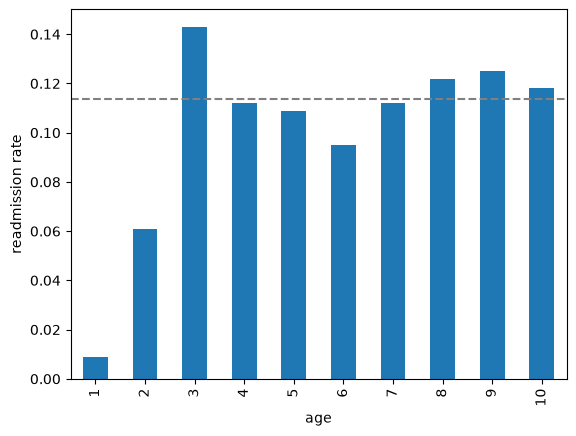

In [3]:
#readmission rate by age group
train = X_train.assign(readmitted_30=y_train)
train.groupby("age")["readmitted_30"].mean().round(3).plot(kind="bar")
plt.axhline(y_train.mean(), ls="--", color="gray")
plt.ylabel("readmission rate")
plt.show()

In [4]:
#readmission rate by past inpatient visits
inpatient = train["number_inpatient"].clip(upper=6)
train.groupby(inpatient)["readmitted_30"].agg(["mean", "count"]).round(3)

,mean,count
number_inpatient,,
0,0.086,46349
1,0.131,13249
2,0.182,5103
3,0.203,2335
4,0.233,1103
5,0.333,579
6,0.392,895


In [5]:
#readmission rate by discharge type
train.groupby("discharge_disposition_id")["readmitted_30"].agg(["mean", "count"]).sort_values("count", ascending=False).head(8).round(3)

,mean,count
discharge_disposition_id,,
1,0.093,42331
3,0.146,9695
6,0.126,9087
18,0.125,2596
2,0.167,1484
22,0.278,1394
5,0.195,799
25,0.083,683


In [6]:
#readmission rate by A1C result
train.groupby("A1Cresult")["readmitted_30"].agg(["mean", "count"]).round(3)

,mean,count
A1Cresult,,
>7,0.103,2637
>8,0.101,5700
None,0.116,57786
Norm,0.102,3490


In [7]:
#readmission rate by payer code
train.groupby("payer_code")["readmitted_30"].agg(["mean", "count"]).sort_values("count", ascending=False).round(3)

,mean,count
payer_code,,
Unknown,0.116,27625
MC,0.120,21901
HM,0.100,4353
SP,0.105,3423
BC,0.096,3254
MD,0.120,2462
CP,0.086,1718
UN,0.100,1711
CM,0.104,1310


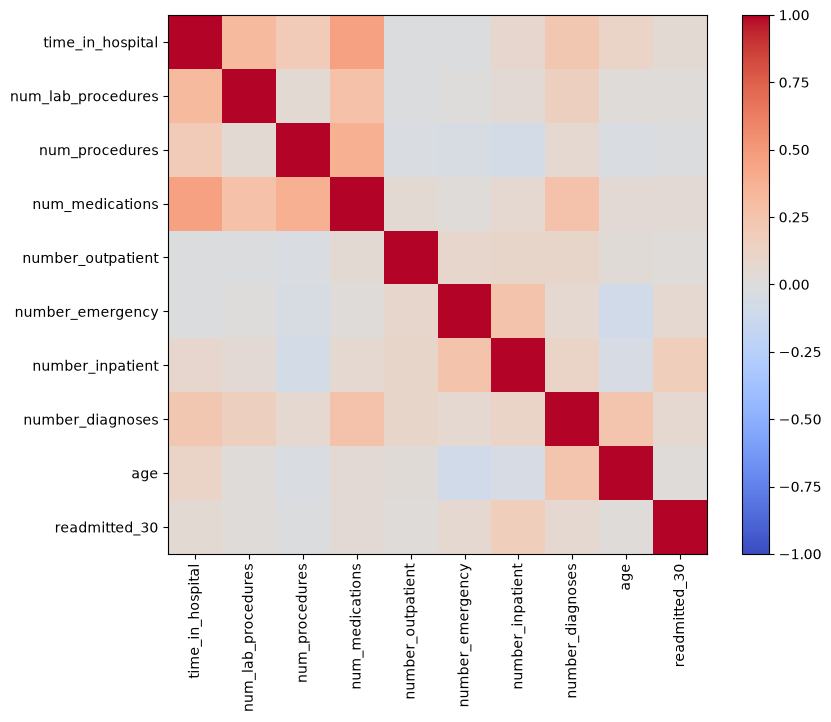

readmitted_30         1.00
number_inpatient      0.17
number_emergency      0.06
number_diagnoses      0.06
time_in_hospital      0.05
num_medications       0.04
num_lab_procedures    0.02
number_outpatient     0.02
age                   0.02
num_procedures       -0.01
Name: readmitted_30, dtype: float64

In [8]:
#correlation between numeric columns
corr = train[numeric_cols + ["age", "readmitted_30"]].corr().round(2)
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.colorbar()
plt.show()
corr["readmitted_30"].sort_values(ascending=False)

In [9]:
#checking lab test mapping
print(glu_map)
print(a1c_map)

{'None': 0, 'Norm': 1, '>200': 2, '>300': 3}
{'None': 0, 'Norm': 1, '>7': 2, '>8': 3}


In [10]:
#comparing A1C before and after mapping
print(X_train["A1Cresult"].value_counts())
print(encode_labs(X_train)["A1Cresult"].value_counts())

A1Cresult
None    57786
>8       5700
Norm     3490
>7       2637
Name: count, dtype: int64
A1Cresult
0    57786
3     5700
1     3490
2     2637
Name: count, dtype: int64


In [11]:
#checking insulin before and after mapping
print(med_map)
print(X_train["insulin"].value_counts())
print(encode_meds(X_train)["insulin"].value_counts())

{'No': 0, 'Down': 1, 'Steady': 2, 'Up': 3}
insulin
No        32507
Steady    21209
Down       8262
Up         7635
Name: count, dtype: int64
insulin
0    32507
2    21209
1     8262
3     7635
Name: count, dtype: int64


In [12]:
#counting patients per medicine
used = (X_train[med_cols] != "No").sum().sort_values()
used

glimepiride-pioglitazone        0
metformin-pioglitazone          1
acetohexamide                   1
metformin-rosiglitazone         1
troglitazone                    3
glipizide-metformin            10
tolbutamide                    14
miglitol                       20
tolazamide                     28
chlorpropamide                 57
acarbose                      219
nateglinide                   479
glyburide-metformin           486
repaglinide                  1088
glimepiride                  3546
rosiglitazone                4427
pioglitazone                 5113
glyburide                    7403
glipizide                    8786
metformin                   13945
insulin                     37106
dtype: int64

In [13]:
#finding medicines with fewer than 100 patients
print(used[used < 100].index.tolist())
print(sorted(used[used < 100].index) == sorted(rare_med_cols))

['glimepiride-pioglitazone', 'metformin-pioglitazone', 'acetohexamide', 'metformin-rosiglitazone', 'troglitazone', 'glipizide-metformin', 'tolbutamide', 'miglitol', 'tolazamide', 'chlorpropamide']
True


In [14]:
#testing the diag grouping
print(icd9_group("250.83"), icd9_group("428"), icd9_group("486"), icd9_group("V57"), icd9_group("Unknown"))

Diabetes Circulatory Respiratory Other Unknown


In [15]:
#comparing unique codes before and after grouping
print("before:", X_train[["diag_1", "diag_2", "diag_3"]].nunique().tolist())
print("after:", group_diagnoses(X_train)[["diag_1", "diag_2", "diag_3"]].nunique().tolist())

before: [683, 697, 748]


after: [10, 10, 10]


In [16]:
#readmission rate by main diagnosis group
diag_groups = group_diagnoses(X_train)["diag_1"]
train.groupby(diag_groups)["readmitted_30"].agg(["mean", "count"]).sort_values("count", ascending=False).round(3)

,mean,count
diag_1,,
Circulatory,0.115,20671
Other,0.119,12443
Respiratory,0.100,9845
Digestive,0.106,6595
Diabetes,0.134,6092
Injury,0.124,4805
Genitourinary,0.110,3504
Musculoskeletal,0.096,3486
Neoplasms,0.107,2160


In [17]:
#counting columns by type
print("one-hot:", len(onehot_cols), onehot_cols)
print("scaled numeric:", len(numeric_cols))
print("scaled ordinal:", len(ordinal_cols))
print("binary 0/1:", len(binary_cols), binary_cols)
print("dropped rare medicines:", len(rare_med_cols))
print("total:", len(onehot_cols + numeric_cols + ordinal_cols + binary_cols + rare_med_cols))

one-hot: 9 ['race', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id']
scaled numeric: 8
scaled ordinal: 14
binary 0/1: 3 ['gender', 'change', 'diabetesMed']
dropped rare medicines: 10
total: 44


In [18]:
#counting categories per one-hot column
group_diagnoses(X_train)[onehot_cols].nunique()

race                         6
payer_code                  18
medical_specialty           70
diag_1                      10
diag_2                      10
diag_3                      10
admission_type_id            8
discharge_disposition_id    21
admission_source_id         16
dtype: int64

In [19]:
#fitting the preprocessor on train
pre = build_preprocessor()
X_train_enc = pre.fit_transform(X_train)
print(X_train.shape, "->", X_train_enc.shape)
pre

(69613, 44) -> (69613, 128)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('encode', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](44,)","['race','gender','age',...,'metformin-pioglitazone','change','diabetesMed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,44
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('labs', ...), ('meds', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consum

In [20]:
#checking infrequent categories
[c for c in X_train_enc.columns if "infrequent" in c]

['payer_code_infrequent_sklearn',
 'medical_specialty_infrequent_sklearn',
 'diag_1_infrequent_sklearn',
 'admission_type_id_infrequent_sklearn',
 'discharge_disposition_id_infrequent_sklearn',
 'admission_source_id_infrequent_sklearn']

In [21]:
#checking text columns, missing values and scaling
print("text columns left:", X_train_enc.select_dtypes(exclude="number").shape[1])
print("missing values:", X_train_enc.isna().sum().sum())
X_train_enc[numeric_cols].agg(["mean", "std"]).round(3)

text columns left: 0
missing values: 0


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
mean,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [22]:
#checking race after one-hot
X_train_enc.filter(like="race_").head()

,race_AfricanAmerican,race_Asian,race_Caucasian,race_Hispanic,race_Other,race_Unknown
encounter_id,,,,,,
149190,0.0,0.0,1.0,0.0,0.0,0.0
64410,1.0,0.0,0.0,0.0,0.0,0.0
500364,0.0,0.0,1.0,0.0,0.0,0.0
16680,0.0,0.0,1.0,0.0,0.0,0.0
35754,0.0,0.0,1.0,0.0,0.0,0.0
